<a href="https://colab.research.google.com/github/Paul412399/PROIECT-PI/blob/main/PigEstimation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!wget -O SwinePose.zip "https://zenodo.org/records/19358700/files/SwinePose_v1.0.zip?download=1"
!unzip -q SwinePose.zip -d /content/SwinePose
!find /content/SwinePose -maxdepth 3 | head -50

--2026-10-28 17:55:07--  https://zenodo.org/records/19358700/files/SwinePose_v1.0.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.51.60, 188.185.47.192, 188.185.40.132, ...
Connecting to zenodo.org (zenodo.org)|188.185.51.60|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 606837441 (579M) [application/octet-stream]
Saving to: ‘SwinePose.zip’

SwinePose.zip       100%[===================>] 578.72M  3.47MB/s    in 3m 24s  

2026-10-28 17:58:32 (2.83 MB/s) - ‘SwinePose.zip’ saved [606837441/606837441]

/content/SwinePose
/content/SwinePose/__MACOSX
/content/SwinePose/__MACOSX/._SwinePose_Zenodo
/content/SwinePose/__MACOSX/SwinePose_Zenodo
/content/SwinePose/__MACOSX/SwinePose_Zenodo/dataset
/content/SwinePose/__MACOSX/SwinePose_Zenodo/._.DS_Store
/content/SwinePose/SwinePose_Zenodo
/content/SwinePose/SwinePose_Zenodo/.DS_Store
/content/SwinePose/SwinePose_Zenodo/dataset
/content/SwinePose/SwinePose_Zenodo/dataset/images
/content/SwinePose/SwinePose_Ze

In [ ]:
import json, os, shutil

base = '/content/SwinePose/SwinePose_Zenodo/dataset'
out  = '/content/swine_yolo'

def convert(json_name, split):
    d = json.load(open(f'{base}/annotations/{json_name}'))
    os.makedirs(f'{out}/images/{split}', exist_ok=True)
    os.makedirs(f'{out}/labels/{split}', exist_ok=True)

    anns = {}
    for a in d['annotations']:
        anns.setdefault(a['image_id'], []).append(a)

    for im in d['images']:
        W, H = im['width'], im['height']
        shutil.copy(f"{base}/images/{im['file_name']}", f"{out}/images/{split}/{im['file_name']}")
        lines = []
        for a in anns.get(im['id'], []):
            x, y, w, h = a['bbox']
            cx, cy = (x + w/2) / W, (y + h/2) / H
            nw, nh = w / W, h / H
            # taiem la marginile imaginii
            cx, cy = min(max(cx, 0), 1), min(max(cy, 0), 1)
            nw, nh = min(nw, 1), min(nh, 1)
            parts = [f'0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}']
            kp = a['keypoints']
            for i in range(0, 45, 3):
                kx, ky, v = kp[i], kp[i+1], int(kp[i+2])
                if v == 0:
                    parts.append('0 0 0')
                else:
                    parts.append(f'{min(max(kx/W,0),1):.6f} {min(max(ky/H,0),1):.6f} {v}')
            lines.append(' '.join(parts))
        name = os.path.splitext(im['file_name'])[0]
        open(f'{out}/labels/{split}/{name}.txt', 'w').write('\n'.join(lines))
    print(split, ':', len(d['images']), 'imagini convertite')

convert('train_videosplit.json', 'train')
convert('val_videosplit.json',   'val')

train : 3099 imagini convertite
val : 679 imagini convertite


In [ ]:
yaml_text = """
path: /content/swine_yolo
train: images/train
val: images/val
kpt_shape: [15, 3]
flip_idx: [0, 1, 9, 10, 12, 13, 6, 11, 14, 2, 3, 7, 4, 5, 8]
names:
  0: pig
"""
open('/content/swine_yolo/data.yaml', 'w').write(yaml_text)

159

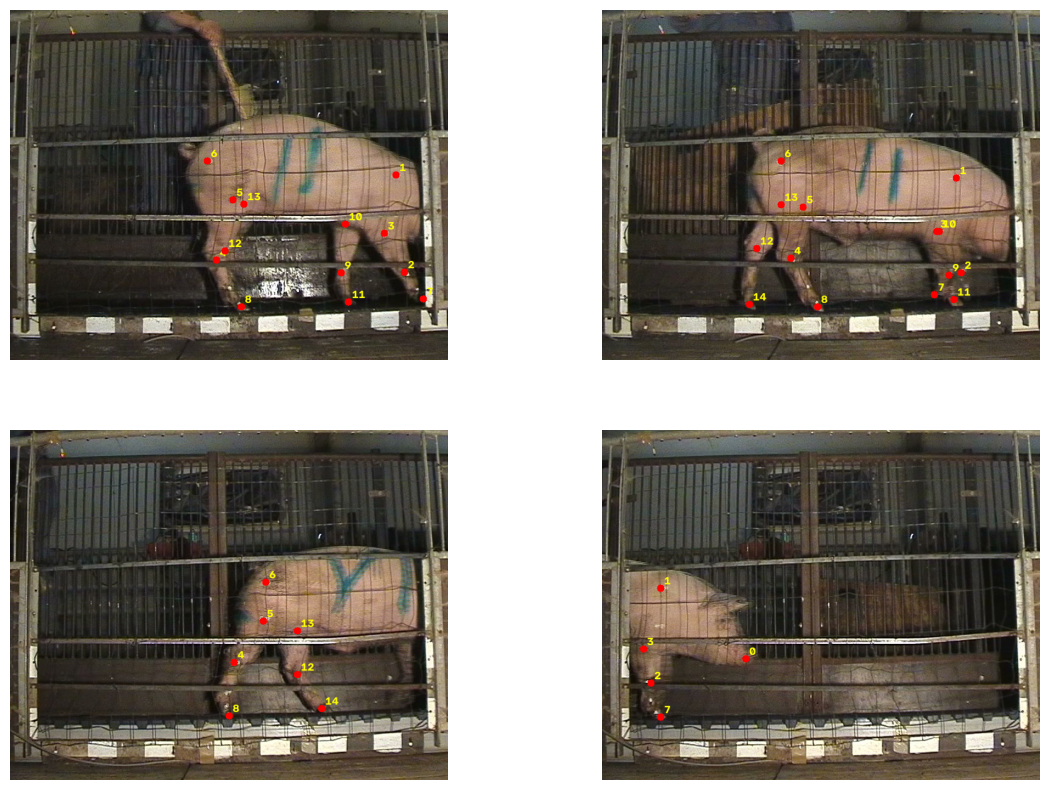

In [ ]:
import cv2, glob, random
import matplotlib.pyplot as plt

imgs = random.sample(glob.glob('/content/swine_yolo/images/train/*.jpg'), 4)
plt.figure(figsize=(14, 10))
for i, p in enumerate(imgs):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    H, W = im.shape[:2]
    lab = open(p.replace('images', 'labels').replace('.jpg', '.txt')).read().split()
    nums = list(map(float, lab))
    kps = nums[5:]
    for k in range(15):
        x, y, v = kps[3*k]*W, kps[3*k+1]*H, kps[3*k+2]
        if v > 0:
            cv2.circle(im, (int(x), int(y)), 6, (255, 0, 0), -1)
            cv2.putText(im, str(k), (int(x)+6, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)
    plt.subplot(2, 2, i+1); plt.imshow(im); plt.axis('off')
plt.show()

In [ ]:
!pip install -q ultralytics
from ultralytics import YOLO

model = YOLO('yolo11s-pose.pt')
model.train(
    data='/content/swine_yolo/data.yaml',
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/swine_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0,

ultralytics.utils.metrics.PoseMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fdbd213cad0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(P)', 'F1-Confidence(P)', 'Precision-Confidence(P)', 'Recall-Confidence(P)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    


0: 512x640 1 pig, 13.2ms
1: 512x640 1 pig, 13.2ms
2: 512x640 1 pig, 13.2ms
3: 512x640 1 pig, 13.2ms
4: 512x640 1 pig, 13.2ms
5: 512x640 1 pig, 13.2ms
Speed: 1.6ms preprocess, 13.2ms inference, 1.9ms postprocess per image at shape (1, 3, 512, 640)
Results saved to /content/runs/pose/predict


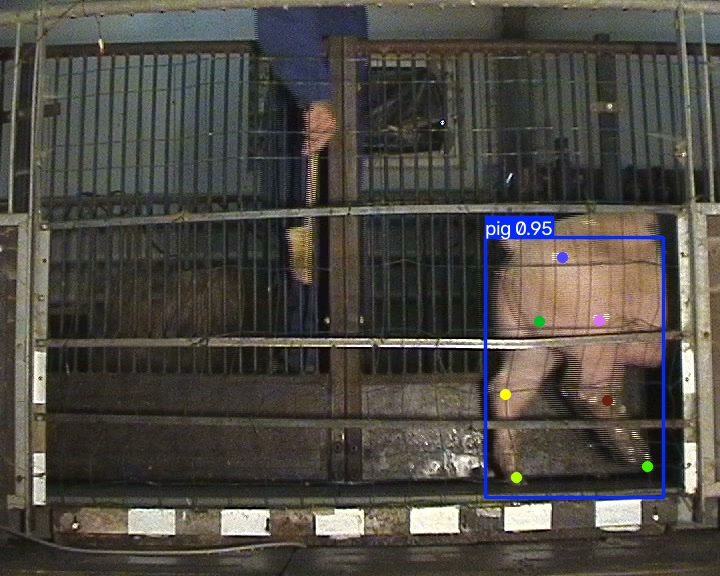

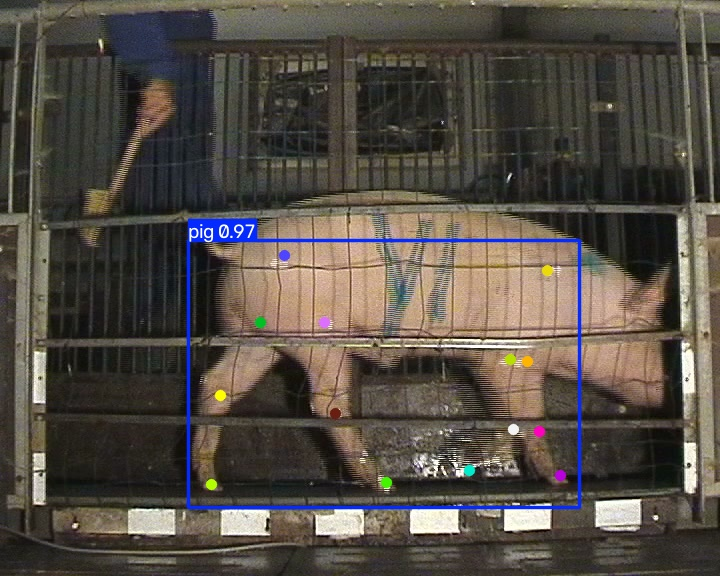

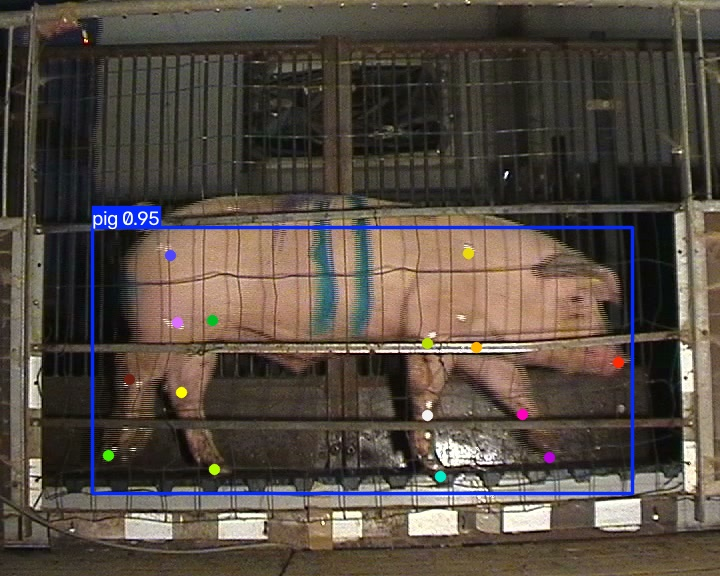

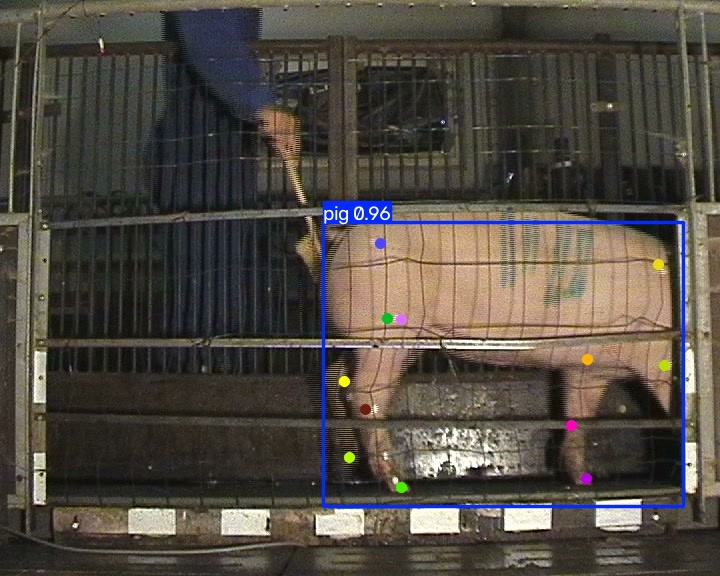

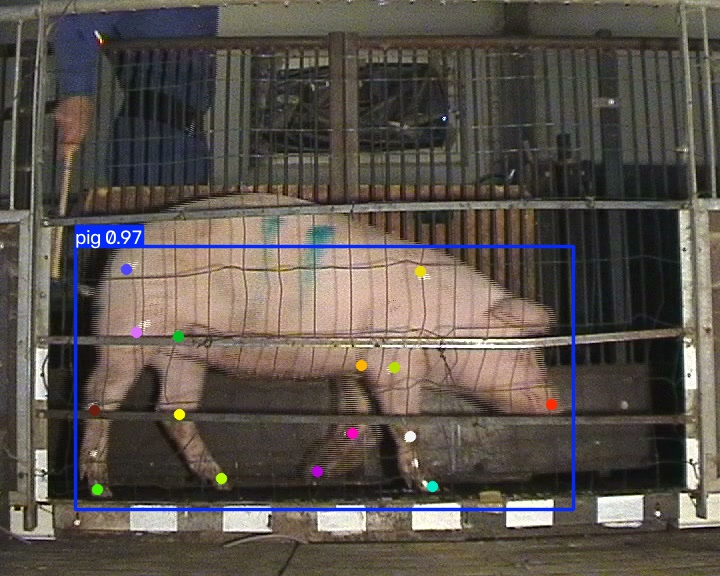

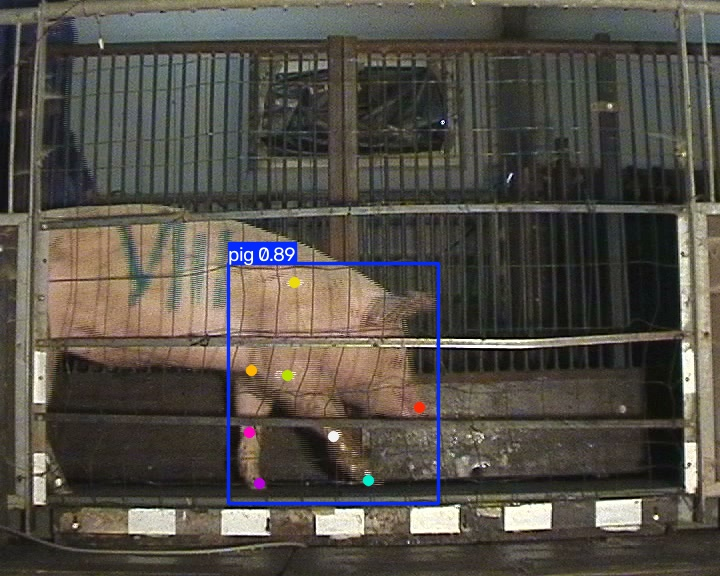

In [ ]:
import os
import glob, random
from IPython.display import Image, display

imgs = random.sample(glob.glob('/content/swine_yolo/images/val/*.jpg'), 6)
results = model.predict(imgs, save=True, conf=0.25)
for r in results:
    display(Image(filename=f'{r.save_dir}/{os.path.basename(r.path)}'))